# Drones Ukraine v2 : 3. PCA et clustering

Analyse **non supervisée** : sans utiliser les étiquettes, quelles structures apparaissent dans les comportements de vol ?

* **Variables** : uniquement les familles physiques (observation, cinématique, altitude). Géographie et heure sont exclues pour regrouper les pistes selon leur manière de voler, pas selon le lieu ou l'heure.
* **Préparation** : logarithme des variables très asymétriques puis standardisation, ajustés sur les jours d'apprentissage seulement et appliqués à toutes les pistes.
* **Méthodes** : PCA, puis K-Means, mélange gaussien (GMM), classification ascendante hiérarchique de Ward et HDBSCAN (densité, avec une catégorie « bruit »).
* **Choix du nombre de groupes** : critères internes uniquement (silhouette, Davies-Bouldin, BIC). Les étiquettes réelles ne servent qu'après coup, pour mesurer l'accord (ARI, NMI, homogénéité, complétude).

In [1]:
import sys
import warnings
from pathlib import Path

# Le notebook s'exécute depuis le dossier v2 (ou depuis la racine du dépôt).
RACINE_V2 = Path.cwd() if (Path.cwd() / "drone_v2").exists() else Path.cwd() / "v2"
sys.path.insert(0, str(RACINE_V2))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from drone_v2 import config, viz

viz.appliquer_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))
%matplotlib inline
import json

from sklearn.cluster import KMeans

from drone_v2 import cartes, donnees, ml
from drone_v2 import non_supervise as ns
from drone_v2.geo import Theatre

tables = donnees.charger_tables()
variables, echantillon = tables["variables"], tables["echantillon"]
train, test = ml.decouper(variables)
prep = ns.Preparation().fit(train)
Z_train, Z = prep.transform(train), prep.transform(variables)
print(f"{len(variables)} pistes, {len(prep.colonnes)} variables physiques standardisées")

7558 pistes, 30 variables physiques standardisées


## 1. Analyse en composantes principales

La PCA est ajustée sur les jours d'apprentissage. On retient le nombre de composantes qui explique 90 % de la variance, puis on vérifie que ces axes captent aussi la variance des jours de test.

8 composantes expliquent 92.0% de la variance (apprentissage)
Part de la variance du test captée par ces 8 composantes : 91.6%


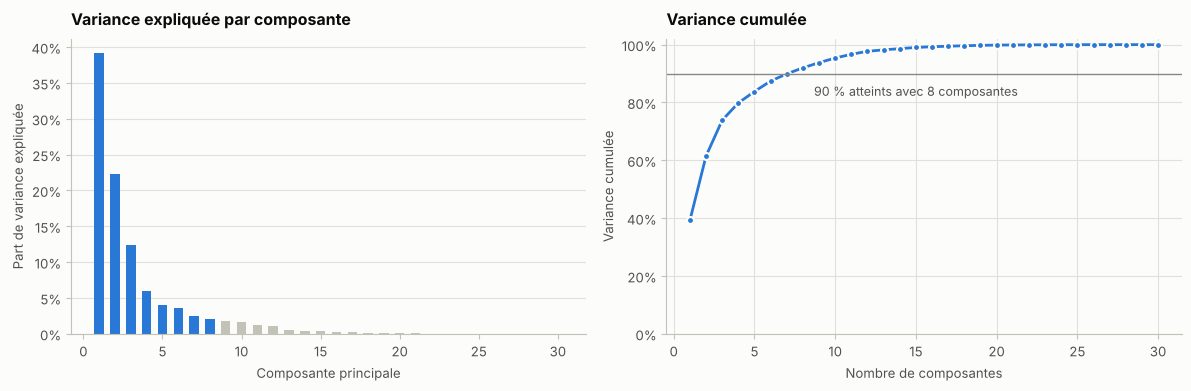

In [2]:
pca, scores, n_comp = ns.acp(Z_train, Z)
variance = np.cumsum(pca.explained_variance_ratio_)
print(f"{n_comp} composantes expliquent {variance[n_comp - 1]:.1%} de la variance (apprentissage)")
Z_test = prep.transform(test)
S_test = pca.transform(Z_test)
print(f"Part de la variance du test captée par ces {n_comp} composantes : "
      f"{S_test[:, :n_comp].var(axis=0).sum() / Z_test.var(axis=0).sum():.1%}")
fig = viz.fig_variance(pca, n_comp)
viz.sauver(fig, "30_pca_variance_v2")
plt.show()

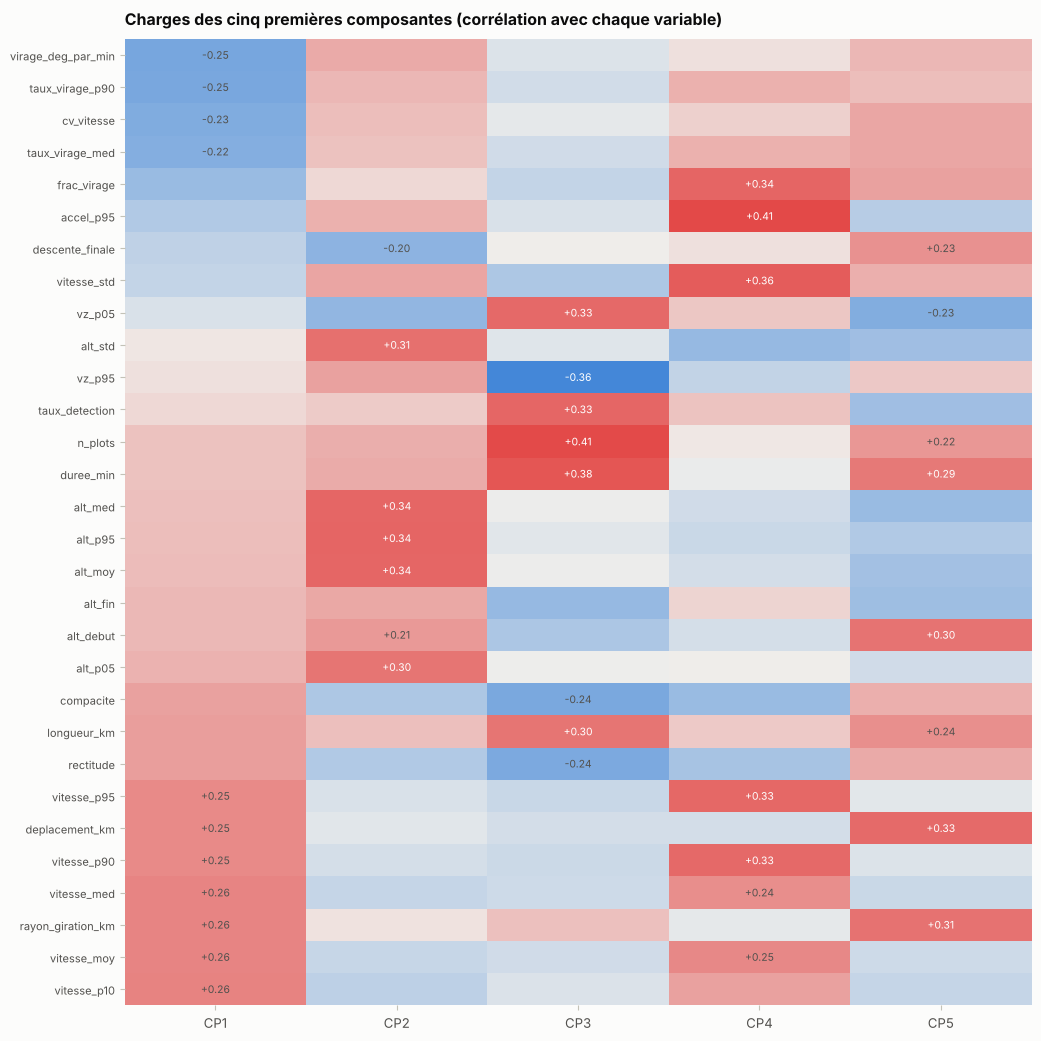

CP1 (39%) : côté positif vitesse_p10, vitesse_moy, rayon_giration_km, vitesse_med ; côté négatif virage_deg_par_min, taux_virage_p90, cv_vitesse, taux_virage_med
CP2 (22%) : côté positif alt_p95, alt_moy, alt_med, alt_std ; côté négatif descente_finale, vz_p05, compacite, rectitude
CP3 (12%) : côté positif n_plots, duree_min, taux_detection, vz_p05 ; côté négatif vz_p95, compacite, rectitude, alt_fin


In [3]:
charges = ns.charges(pca, prep.colonnes, 5)
fig = viz.fig_charges(charges, "Charges des cinq premières composantes (corrélation avec chaque variable)")
viz.sauver(fig, "31_pca_charges_v2")
plt.show()
for k in range(3):
    col = charges.iloc[:, k]
    plus = ", ".join(col.sort_values(ascending=False).head(4).index)
    moins = ", ".join(col.sort_values().head(4).index)
    print(f"CP{k + 1} ({pca.explained_variance_ratio_[k]:.0%}) : côté positif {plus} ; côté négatif {moins}")

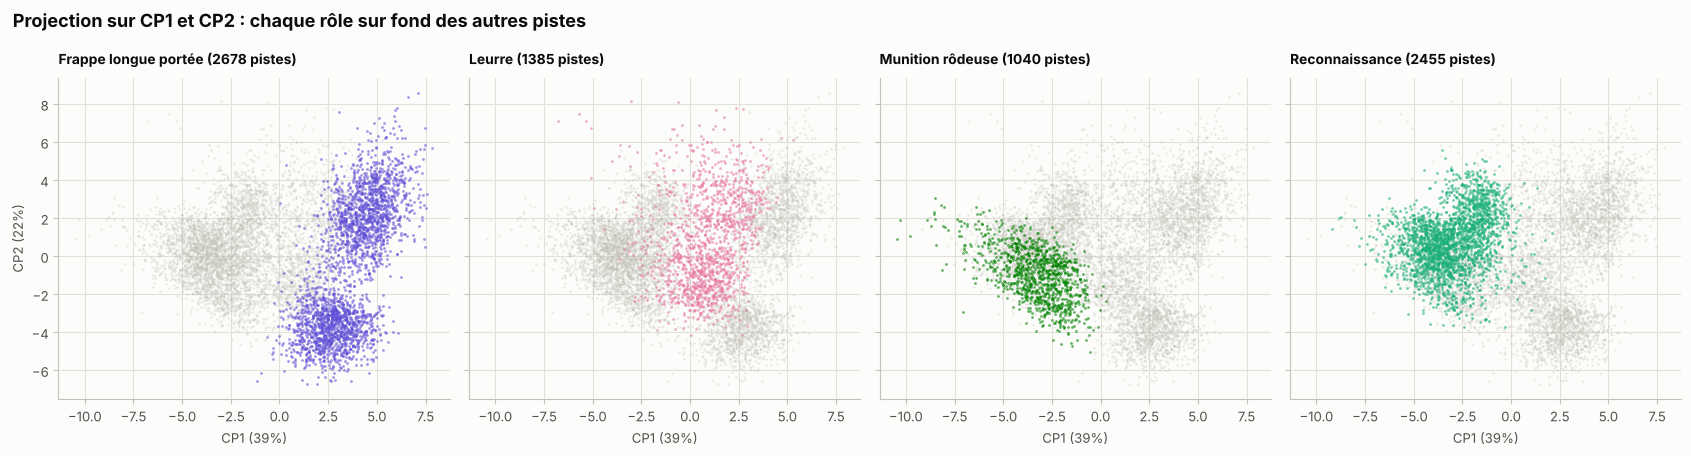

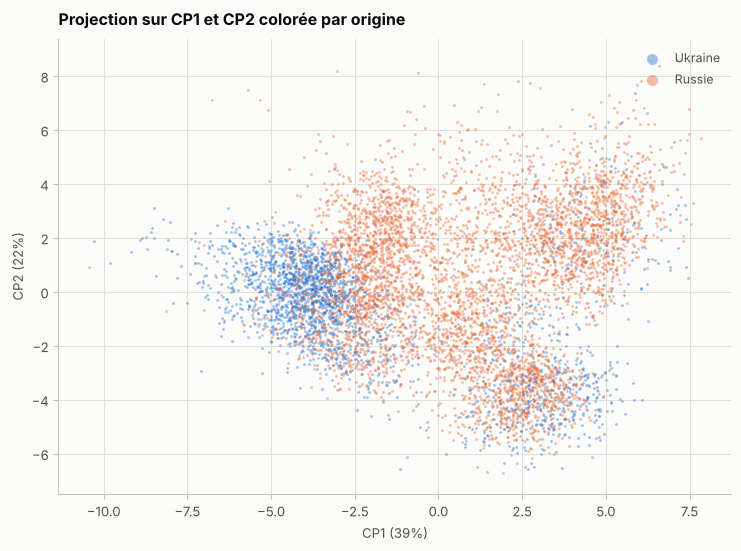

Projection 3D interactive : cartes/pca_3d_v2.html


In [4]:
fig = viz.fig_projection_roles(scores, variables.role, pca,
                               titre="Projection sur CP1 et CP2 : chaque rôle sur fond des autres pistes")
viz.sauver(fig, "32_pca_projection_roles_v2")
plt.show()
fig, ax = plt.subplots(figsize=(7.5, 5.6))
for origine, couleur in viz.COULEUR_ORIGINE.items():
    m = (variables.origine == origine).to_numpy()
    ax.scatter(scores[m, 0], scores[m, 1], s=4, color=couleur, alpha=0.45, linewidth=0, label=origine,
               rasterized=True)
ax.set_xlabel(f"CP1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"CP2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Projection sur CP1 et CP2 colorée par origine")
ax.legend(loc="upper right", markerscale=4, labelcolor=viz.ENCRE_2)
fig.tight_layout()
viz.sauver(fig, "33_pca_projection_origine_v2")
plt.show()
html = cartes.pca_3d(scores, variables, pca, config.CARTES / "pca_3d_v2.html")
print("Projection 3D interactive :", Path(html).relative_to(RACINE_V2))

## 2. Choix du nombre de groupes

* K-Means : k qui maximise la silhouette.
* Mélange gaussien : le BIC baisse presque toujours quand k augmente ; on retient le plus petit k au-delà duquel le gain relatif de BIC passe sous 1 %.

,k,inertie,silhouette,davies_bouldin,calinski_harabasz,bic_gmm,aic_gmm
0,2,138 512.675,0.314,1.342,3 748.670,189 612.918,188 996.116
1,3,105 840.562,0.324,1.089,3 618.688,182 238.346,181 309.678
2,4,87 342.843,0.316,1.245,3 456.256,174 404.961,173 164.426
3,5,79 455.332,0.280,1.273,3 036.591,172 715.768,171 163.367
4,6,72 479.162,0.287,1.294,2 808.115,169 274.647,167 410.379
5,7,67 309.239,0.293,1.225,2 616.163,167 838.802,165 662.668
6,8,62 598.165,0.276,1.252,2 492.041,166 887.202,164 399.203
7,9,58 825.897,0.253,1.321,2 380.575,165 688.570,162 888.704
8,10,55 907.848,0.252,1.380,2 269.991,165 269.938,162 158.205
9,11,53 304.220,0.244,1.410,2 179.355,164 953.037,161 529.438


K-Means : k = 3 (silhouette 0.324) ; mélange gaussien : k = 4


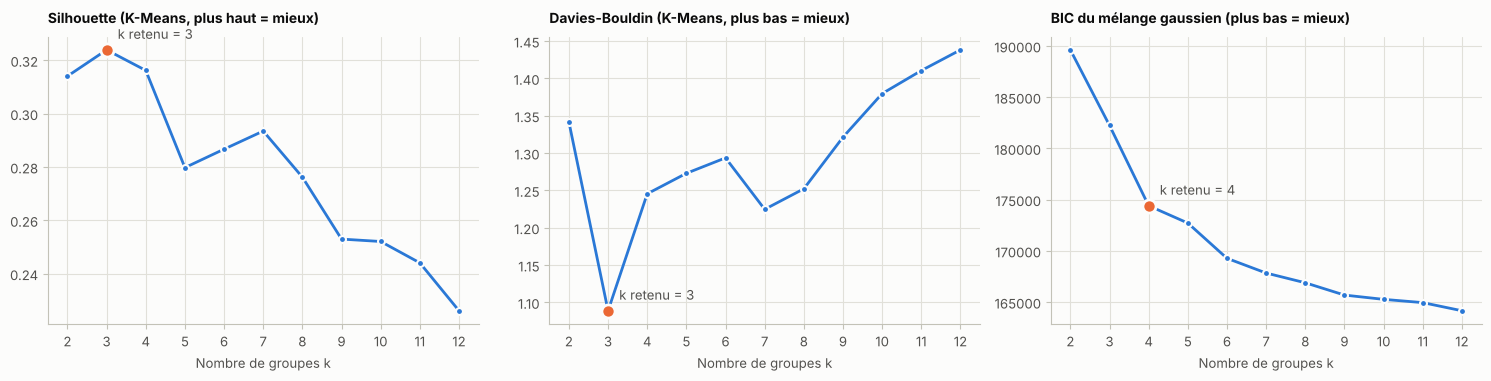

In [5]:
S = scores[:, :n_comp]
choix = ns.choix_k(S)
display(choix)
k_km = int(choix.loc[choix.silhouette.idxmax(), "k"])
bic = choix.set_index("k").bic_gmm
gain = (bic - bic.shift(-1)) / bic.abs()
k_gmm = int(gain[gain < 0.01].index.min()) if (gain < 0.01).any() else int(bic.idxmin())
print(f"K-Means : k = {k_km} (silhouette {choix.silhouette.max():.3f}) ; mélange gaussien : k = {k_gmm}")
fig = viz.fig_choix_k(choix, k_km, k_gmm)
viz.sauver(fig, "34_choix_k_v2")
plt.show()

## 3. Partitions et accord avec les classes réelles

* **Critères internes** : silhouette (plus haut = groupes mieux séparés), Davies-Bouldin (plus bas = mieux).
* **Critères externes**, calculés après coup : ARI (0 = accord dû au hasard, 1 = identique), NMI, homogénéité (chaque groupe contient-il un seul rôle ?) et complétude (chaque rôle tient-il dans un seul groupe ?). Pour HDBSCAN, les points classés « bruit » sont exclus de ces calculs.

,methode,n_groupes,part_bruit,silhouette,davies_bouldin,ARI_role,NMI_role,ARI_origine,NMI_origine,ARI_modele,NMI_modele,homogeneite_role,completude_role
0,K-Means,3,0.000,0.324,1.089,0.409,0.476,0.026,0.074,0.142,0.359,0.428,0.538
1,Mélange gaussien (GMM),4,0.000,0.267,1.372,0.403,0.506,0.040,0.048,0.214,0.395,0.518,0.494
2,CAH de Ward,3,0.000,0.286,1.262,0.442,0.525,0.040,0.079,0.179,0.397,0.474,0.590
3,HDBSCAN,3,0.395,0.327,1.049,0.681,0.776,0.163,0.090,0.363,0.553,0.676,0.911


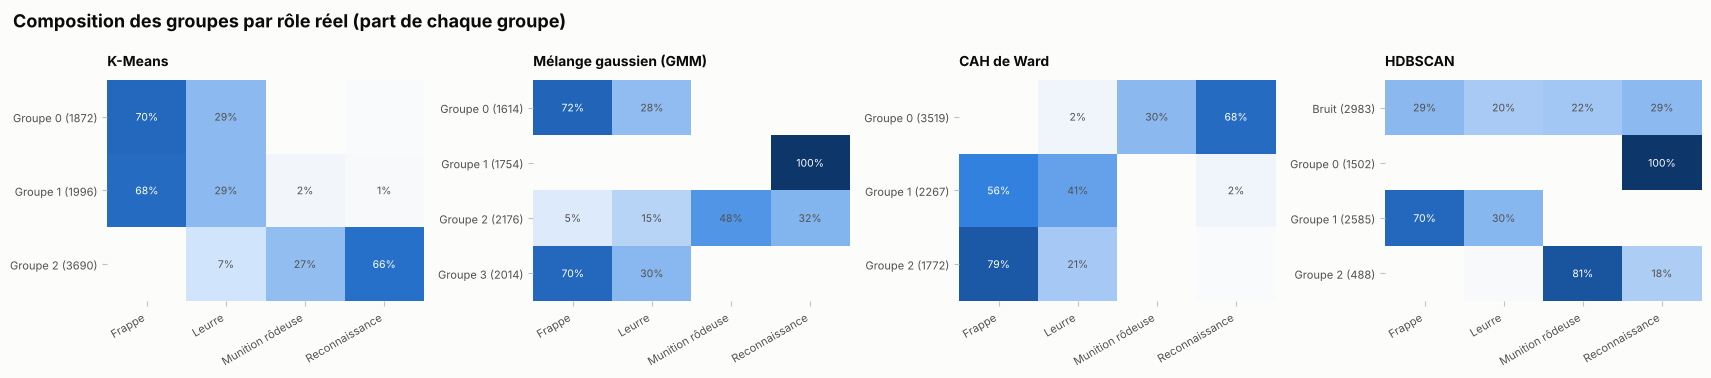

In [6]:
partitions = ns.partitions(S, k_km, k_gmm)
evaluation = ns.evaluer_partitions(S, partitions, variables)
display(evaluation)
fig = viz.fig_contingences(partitions, variables.role, "Composition des groupes par rôle réel (part de chaque groupe)")
viz.sauver(fig, "35_contingences_roles_v2")
plt.show()

In [7]:
partitions_4 = {f"{nom} (k = 4)": lab for nom, lab in ns.partitions(S, 4, 4).items() if nom != "HDBSCAN"}
evaluation_4 = ns.evaluer_partitions(S, partitions_4, variables)
display(Markdown("**Même analyse en imposant k = 4 (nombre de rôles)**"))
display(evaluation_4[["methode", "silhouette", "ARI_role", "NMI_role", "homogeneite_role", "completude_role"]])

**Même analyse en imposant k = 4 (nombre de rôles)**

,methode,silhouette,ARI_role,NMI_role,homogeneite_role,completude_role
0,K-Means (k = 4),0.316,0.453,0.528,0.541,0.515
1,Mélange gaussien (GMM) (k = 4),0.267,0.403,0.506,0.518,0.494
2,CAH de Ward (k = 4),0.287,0.480,0.575,0.589,0.562


## 4. Stabilité

La partition K-Means est refaite sur 25 sous-échantillons de 80 % des pistes. Un ARI proche de 1 entre la partition de référence et chaque nouvelle partition signifie que les groupes ne sont pas un artefact du tirage.

In [8]:
stabilite = ns.stabilite(S, k_km, n=25)
print(f"ARI de stabilité (k = {k_km}) : moyenne {stabilite.mean():.3f}, minimum {stabilite.min():.3f}")

ARI de stabilité (k = 3) : moyenne 0.997, minimum 0.994


## 5. Profils des groupes K-Means

In [9]:
profils = ns.profils(variables, partitions["K-Means"])
composition = pd.crosstab(partitions["K-Means"], variables.role.to_numpy(), normalize="index")
profils["role_majoritaire"] = composition.idxmax(axis=1)
profils["part_role_majoritaire"] = composition.max(axis=1)
display(profils)
for g, r in profils.iterrows():
    print(f"Groupe {g} : {int(r.effectif)} pistes, vitesse médiane {r.vitesse_med:.0f} km/h, altitude médiane "
          f"{r.alt_med:.0f} m, rectitude {r.rectitude:.2f}, durée médiane {r.duree_min:.0f} min ; "
          f"rôle majoritaire {r.role_majoritaire} ({r.part_role_majoritaire:.0%})")

,vitesse_med,alt_med,duree_min,rectitude,taux_virage_med,compacite,vz_p05,effectif,role_majoritaire,part_role_majoritaire
groupe,,,,,,,,,,
0,149.053,2 221.990,132.333,0.918,0.166,0.272,-5.383,1872,Frappe longue portée,0.703
1,148.511,463.981,80.500,0.965,0.124,0.282,-2.946,1996,Frappe longue portée,0.682
2,75.097,889.321,69.083,0.263,0.357,0.119,-3.316,3690,Reconnaissance,0.656


Groupe 0 : 1872 pistes, vitesse médiane 149 km/h, altitude médiane 2222 m, rectitude 0.92, durée médiane 132 min ; rôle majoritaire Frappe longue portée (70%)
Groupe 1 : 1996 pistes, vitesse médiane 149 km/h, altitude médiane 464 m, rectitude 0.97, durée médiane 80 min ; rôle majoritaire Frappe longue portée (68%)
Groupe 2 : 3690 pistes, vitesse médiane 75 km/h, altitude médiane 889 m, rectitude 0.26, durée médiane 69 min ; rôle majoritaire Reconnaissance (66%)


## 6. Visualisation t-SNE

Le t-SNE sert uniquement à visualiser (les distances entre groupes éloignés n'y ont pas de sens quantitatif). Il est calculé sur 3 000 pistes tirées au hasard, dans l'espace des composantes retenues.

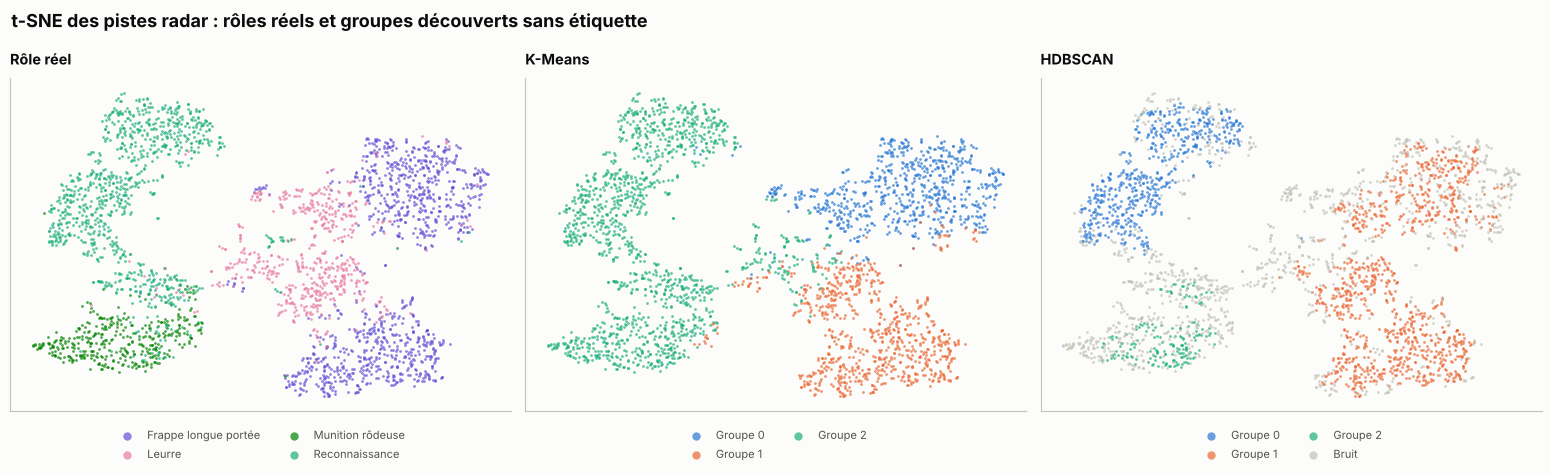

In [10]:
idx, emb = ns.tsne(S)
fig = viz.fig_tsne(emb, {"Rôle réel": variables.role.to_numpy()[idx], "K-Means": partitions["K-Means"][idx],
                         "HDBSCAN": partitions["HDBSCAN"][idx]},
                   "t-SNE des pistes radar : rôles réels et groupes découverts sans étiquette")
viz.sauver(fig, "36_tsne_v2")
plt.show()

## 7. Les groupes sur la carte

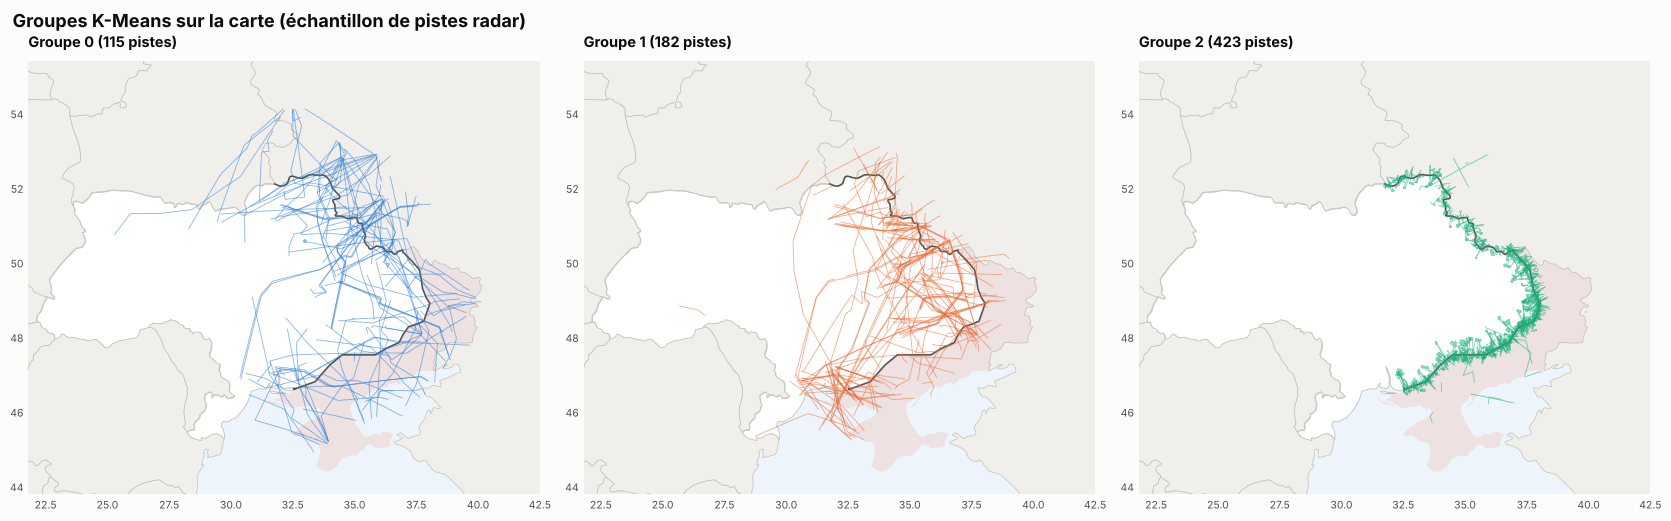

Carte interactive : cartes/carte_groupes_v2.html


In [11]:
theatre = Theatre()
groupes = pd.Series(partitions["K-Means"], index=variables.piste_id.to_numpy())
groupes_ech = groupes[groupes.index.isin(set(echantillon.piste_id))]
fig = viz.fig_carte_groupes(theatre, echantillon, groupes_ech,
                            "Groupes K-Means sur la carte (échantillon de pistes radar)")
viz.sauver(fig, "37_carte_groupes_v2")
plt.show()
html = cartes.carte_groupes(theatre, echantillon, groupes, profils, config.CARTES / "carte_groupes_v2.html")
print("Carte interactive :", Path(html).relative_to(RACINE_V2))

## 8. Sauvegarde

In [12]:
sortie = pd.DataFrame(dict(piste_id=variables.piste_id, kmeans=partitions["K-Means"],
                          gmm=partitions["Mélange gaussien (GMM)"], cah_ward=partitions["CAH de Ward"],
                          hdbscan=partitions["HDBSCAN"], cp1=scores[:, 0], cp2=scores[:, 1], cp3=scores[:, 2]))
sortie.to_csv(config.RAPPORTS / "groupes_non_supervises_v2.csv", index=False, float_format="%.4f")
resume_ns = dict(
    n_composantes=n_comp, variance_expliquee=float(variance[n_comp - 1]),
    variance_par_composante=pca.explained_variance_ratio_[:n_comp].tolist(),
    k_kmeans=k_km, k_gmm=k_gmm, choix_k=choix.to_dict(orient="records"),
    evaluation=evaluation.to_dict(orient="records"), evaluation_k4=evaluation_4.to_dict(orient="records"),
    stabilite_ari_moyen=float(stabilite.mean()), stabilite_ari_min=float(stabilite.min()),
    profils=profils.reset_index().to_dict(orient="records"))
with open(config.RAPPORTS / "non_supervise_v2.json", "w", encoding="utf-8") as f:
    json.dump(resume_ns, f, indent=2, ensure_ascii=False, default=float)
print("Résultats enregistrés.")

Résultats enregistrés.
